### Titanic - inżyniera cech 2

Łukasz Całka <br>
Uczenie Maszynowe

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("Titanic_zmieniony.csv")

In [6]:
df.info()
df.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   pclass        1309 non-null   int64  
 1   survived      1309 non-null   int64  
 2   name          1309 non-null   str    
 3   sex           1309 non-null   str    
 4   age           1046 non-null   float64
 5   sibsp         1309 non-null   int64  
 6   parch         1309 non-null   int64  
 7   ticket        1309 non-null   str    
 8   fare          1308 non-null   float64
 9   cabin         295 non-null    str    
 10  embarked      1307 non-null   str    
 11  boat          486 non-null    str    
 12  body          121 non-null    float64
 13  home.dest     745 non-null    str    
 14  CabinReduced  295 non-null    str    
dtypes: float64(3), int64(4), str(8)
memory usage: 153.5 KB


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,CabinReduced
count,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,295,1307,486,121.000000,745,295
unique,NaN,NaN,1307,2,NaN,NaN,NaN,929,NaN,186,3,27,NaN,369,8
top,NaN,NaN,"Connolly, Miss. Kate",male,NaN,NaN,NaN,CA. 2343,NaN,C23 C25 C27,S,13,NaN,"New York, NY",C
freq,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,6,914,39,NaN,64,94
mean,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN,NaN
std,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN
25%,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN,NaN
50%,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN,NaN
75%,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN,NaN


In [20]:
#col_name = ['cabin', 'CabinReduced', 'sex']
col_name = ['CabinReduced', 'sex']
X = df[col_name]
y = df['survived']

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(1047, 3) (262, 3)
survived
0    0.617956
1    0.382044
Name: proportion, dtype: float64
survived
0    0.618321
1    0.381679
Name: proportion, dtype: float64


Opis parametrów:

- test_size określa proporcję podziału danych czyli jaki ułamek danych znajdzie się w zbiorze testowym (reszta będzie w zbiorze treningowym);
- random_state ustawia ziarno generatora liczb losowych, dzięki czemu skrypt przy każdym uruchomieniu zachowa się tak samo
- stratify po przypisaniu zmiennej docelowej próbuje zachować proporcję klas, czyli aby zmienna modelowana miała taki sam rozkład w obu zbiorach co w oryginalnych danych.

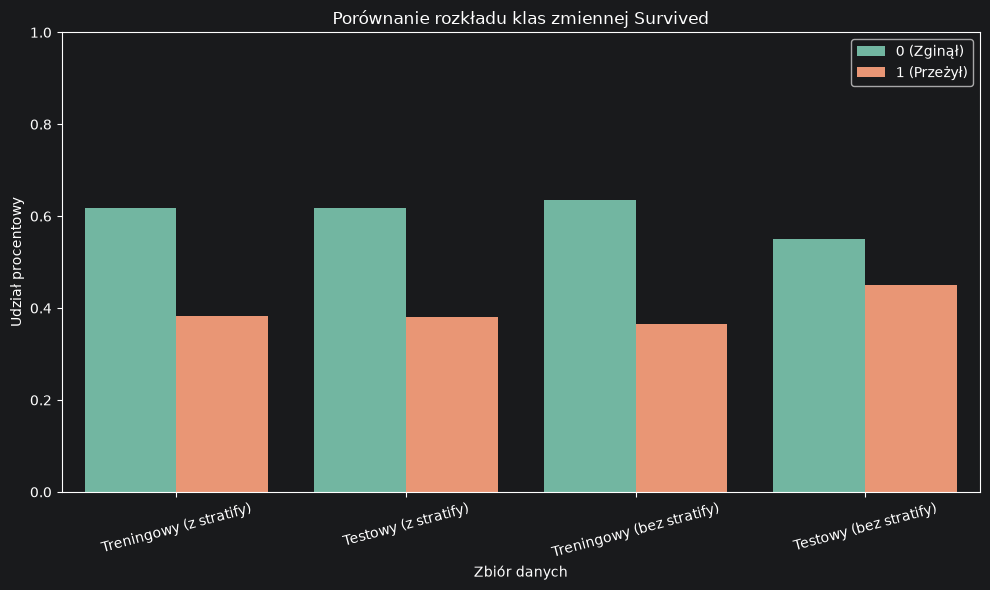

In [15]:
X_train_no_strat, X_test_no_strat, y_train_no_strat, y_test_no_strat = train_test_split(
    X, y, test_size=0.2, random_state=42
)


dist_strat_train = y_train.value_counts(normalize=True).sort_index()
dist_strat_test = y_test.value_counts(normalize=True).sort_index()

dist_no_strat_train = y_train_no_strat.value_counts(normalize=True).sort_index()
dist_no_strat_test = y_test_no_strat.value_counts(normalize=True).sort_index()

plot_data = pd.DataFrame({
    'Survived': ['0 (Zginął)', '1 (Przeżył)'] * 4,
    'Proporcja': pd.concat([
        dist_strat_train, dist_strat_test,
        dist_no_strat_train, dist_no_strat_test
    ]).values,
    'Zbiór danych': [
        'Treningowy (z stratify)', 'Treningowy (z stratify)',
        'Testowy (z stratify)', 'Testowy (z stratify)',
        'Treningowy (bez stratify)', 'Treningowy (bez stratify)',
        'Testowy (bez stratify)', 'Testowy (bez stratify)'
    ]
})


plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x='Zbiór danych', y='Proporcja', hue='Survived', palette='Set2')

plt.title('Porównanie rozkładu klas zmiennej Survived')
plt.ylabel('Udział procentowy')
plt.xticks(rotation=15)
plt.ylim(0, 1) # Ustawiamy oś Y od 0 do 1 (0% - 100%)
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
for col in col_name:
    print(f'\n{col}:')
    print('Train:')
    print(X_train[col].value_counts(normalize=True))
    print('Test:')
    print(X_test[col].value_counts(normalize=True))


cabin:
Train:
cabin
C23 C25 C27        0.022222
B57 B59 B63 B66    0.017778
C78                0.017778
B96 B98            0.017778
E34                0.013333
                     ...   
C65                0.004444
A19                0.004444
B52 B54 B56        0.004444
A26                0.004444
C105               0.004444
Name: proportion, Length: 155, dtype: float64
Test:
cabin
F2                 0.042857
D35                0.028571
E33                0.028571
F33                0.028571
E121               0.028571
B5                 0.028571
B28                0.028571
C55 C57            0.028571
G6                 0.028571
C101               0.028571
B51 B53 B55        0.014286
D                  0.014286
C123               0.014286
F E46              0.014286
E52                0.014286
D17                0.014286
B10                0.014286
B101               0.014286
B57 B59 B63 B66    0.014286
F G73              0.014286
C23 C25 C27        0.014286
C51                0.0142

In [21]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
for col in col_name:
    encoder.fit(X_train[col].astype(str))
    X_train[col + '_map'] = encoder.transform(X_train[col].astype(str))
    X_test[col + '_map'] = encoder.transform(X_test[col].astype(str))

Kod nie zadziałał na początku, usunąć należało kolumnę 'cabin', która zawierała zbyt wiele unikalnych wartości

In [24]:
print("Porównanie wartości przed i po kodowaniu:")
print(X_train[['sex', 'sex_map']].head(10))

Porównanie wartości przed i po kodowaniu:
         sex  sex_map
999   female        0
392   female        0
628   female        0
1165    male        1
604   female        0
605     male        1
25      male        1
1278    male        1
196     male        1
1292    male        1


In [25]:
print(X_train.isnull().sum())
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

cabin               822
CabinReduced        822
sex                   0
cabin_map             0
CabinReduced_map      0
sex_map               0
dtype: int64


In [26]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='most_frequent')
X_train_imputed = imputer.fit_transform(X_train)

To imputacja przy użyciu najczęściej występującej wartości. Ma duży sens przy danych kategorycznych, gdzie nie da się policzyć statystyk opisowych i na ich podstawie dokonać imputacji.

In [27]:
for col in col_name:
    unikalne_przed = X_train[col].nunique()
    unikalne_po = X_train[col + '_map'].nunique()

    print(f"{col}:")
    print(f" - Unikalne wartości przed kodowaniem: {unikalne_przed}")
    print(f" - Unikalne wartości po kodowaniu: {unikalne_po}\n")

CabinReduced:
 - Unikalne wartości przed kodowaniem: 9
 - Unikalne wartości po kodowaniu: 9

sex:
 - Unikalne wartości przed kodowaniem: 2
 - Unikalne wartości po kodowaniu: 2



Kodowanie zmiennych nie zmienia liczby ich unikalnych wartości - liczba kategorii zostaje bez zmian.

### Wnioski z ćwiczenia
Reprezentatywność - ważnym jest aby zbiór testowy i treningowy były do siebie podobne. Dzięki temu model będzie się uczył właściwych wzorców i jego wyniki będą wiarygodne.

Wpływ imputacji i kodowania - kodowanie jest niezbędne, by zamienić tekst na zrozumiałe dla modelu liczby bez utraty ich unikalności. Imputacja pozwala zachować wiersze z brakami, należy jednak zastosować jej odpowiednią metodę zależną od potrzeb oraz typu danych z jakimi mamy doczynienia.

Znaczenie stratyfikacji - zapewnia ona zachowanie oryginalnych rozkładów klas podczas podziału. Pozwala to uczyć zbiór na właściwych wzorcach i uniknąć nadliczebności jakiejś klasy, w którymś ze zbiorów.